# PulmoSight 11 — Ensembles: Can Combining the Three Models Beat EfficientNet-B0?

## Setup

In [1]:
import json, math, os, random, time
from collections import deque
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.io as tvio
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if DEVICE.type == "cuda" and torch.cuda.is_bf16_supported() else torch.float16
IMAGE_SIZE, MEAN, STD = 512, 0.449, 0.226
CLASSES = ["normal", "tb"]
SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything()
torch.backends.cudnn.benchmark = True
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

print(f"Project root : {ROOT}")
print(f"PyTorch      : {torch.__version__}")
print(f"Device       : {DEVICE} ({torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'})")
print(f"AMP dtype    : {AMP_DTYPE}")

Project root : F:\Projects\pulmoSight\TB Project
PyTorch      : 2.11.0+cu128
Device       : cuda (NVIDIA GeForce RTX 4060 Laptop GPU)
AMP dtype    : torch.bfloat16


In [2]:
def read_xray(path):
    """Decode a cached 8-bit grayscale PNG -> uint8 tensor [1, H, W]."""
    img = tvio.decode_image(tvio.read_file(str(path)), mode=tvio.ImageReadMode.GRAY)
    if img.shape[-2:] != (IMAGE_SIZE, IMAGE_SIZE):
        img = F.interpolate(img[None].float(), size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear",
                            antialias=True, align_corners=False)[0].round().clamp(0, 255).to(torch.uint8)
    return img


class XrayLoader:
    """Thread-pool batch loader.

    Windows notebooks cannot pickle notebook-defined Datasets into DataLoader worker
    processes, so we decode PNGs with threads (decoding releases the GIL) and do all
    augmentation on the GPU instead.
    """
    def __init__(self, frame, batch_size=32, shuffle=False, drop_last=False, threads=12, prefetch=6, seed=SEED):
        self.paths = [ROOT / p for p in frame["path"]]
        self.labels = frame["label"].to_numpy(dtype=np.int64)
        self.batch_size, self.shuffle, self.drop_last = batch_size, shuffle, drop_last
        self.threads, self.prefetch = threads, prefetch
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        n = len(self.paths)
        return n // self.batch_size if self.drop_last else math.ceil(n / self.batch_size)

    def __iter__(self):
        n = len(self.paths)
        order = self.rng.permutation(n) if self.shuffle else np.arange(n)
        batches = [order[i:i + self.batch_size] for i in range(0, n, self.batch_size)]
        if self.drop_last and len(batches[-1]) < self.batch_size:
            batches = batches[:-1]
        with ThreadPoolExecutor(self.threads) as pool:
            pending, it = deque(), iter(batches)
            submit = lambda b: (b, [pool.submit(read_xray, self.paths[i]) for i in b])
            for _ in range(self.prefetch):
                b = next(it, None)
                if b is not None:
                    pending.append(submit(b))
            while pending:
                b, futures = pending.popleft()
                nxt = next(it, None)
                if nxt is not None:
                    pending.append(submit(nxt))
                x = torch.stack([f.result() for f in futures])
                yield x, torch.from_numpy(self.labels[b])


def gpu_augment(x):
    """Random affine (+-7 deg, +-4% shift, 0.93-1.07 zoom) + brightness/contrast jitter, on GPU."""
    b, dev = x.size(0), x.device
    u = lambda: torch.rand(b, device=dev) * 2 - 1
    angle, scale = u() * math.radians(7), 1 + u() * 0.07
    tx, ty = u() * 0.08, u() * 0.08            # grid spans [-1, 1] -> 4% of the image
    cos, sin = torch.cos(angle) / scale, torch.sin(angle) / scale
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    bright = 1 + u().view(b, 1, 1, 1) * 0.15
    contrast = 1 + u().view(b, 1, 1, 1) * 0.15
    x = x * bright
    m = x.mean(dim=(2, 3), keepdim=True)
    return ((x - m) * contrast + m).clamp(0, 1)


def prepare_batch(x, augment=False):
    x = x.to(DEVICE, non_blocking=True).float().div_(255)
    if augment:
        x = gpu_augment(x)
    return ((x - MEAN) / STD).contiguous(memory_format=torch.channels_last)


splits = pd.read_csv(ROOT / "splits" / "splits.csv")
train_df = splits[splits.split == "train"].reset_index(drop=True)
val_df = splits[splits.split == "val"].reset_index(drop=True)
test_df = splits[splits.split == "test"].reset_index(drop=True)
print(splits.groupby(["split", "label"]).size().unstack().rename(columns=dict(enumerate(CLASSES))))

label  normal    tb
split              
test      861   820
train    6860  6585
val       850   809


In [3]:
def autocast():
    return torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type == "cuda")


@torch.no_grad()
def predict_logits(model, loader):
    model.eval()
    logits, labels = [], []
    for x, y in loader:
        with autocast():
            out = model(prepare_batch(x))
        logits.append(out.float().cpu()); labels.append(y)
    return torch.cat(logits).numpy(), torch.cat(labels).numpy()


def binary_metrics(logits, labels, threshold=0.5):
    p = torch.from_numpy(logits).softmax(1)[:, 1].numpy()
    pred = p >= threshold
    pos = labels == 1
    tp, tn = int((pred & pos).sum()), int((~pred & ~pos).sum())
    fp, fn = int((pred & ~pos).sum()), int((~pred & pos).sum())
    return {"auroc": float(roc_auc_score(labels, p)), "acc": (tp + tn) / len(labels),
            "sensitivity": tp / max(tp + fn, 1), "specificity": tn / max(tn + fp, 1)}


def fit(model, train_loader, val_loader, optimizer, scheduler, epochs, criterion, ckpt_path, meta,
        patience=6, history=None, stage="", before_epoch=None):
    """Train with early stopping on validation AUROC. Saves the best checkpoint to ckpt_path."""
    history = [] if history is None else history
    best = max([h["val_auroc"] for h in history], default=-1.0)
    bad = 0
    start = len(history) + 1
    for epoch in range(start, start + epochs):
        t0 = time.time()
        model.train()
        if before_epoch:
            before_epoch(model)
        loss_sum = torch.zeros((), device=DEVICE); correct = torch.zeros((), device=DEVICE); seen = 0
        for x, y in train_loader:
            x, y = prepare_batch(x, augment=True), y.to(DEVICE, non_blocking=True)
            with autocast():
                out = model(x)
            loss = criterion(out.float(), y)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            optimizer.step()
            scheduler.step()
            loss_sum += loss.detach() * y.size(0); correct += (out.argmax(1) == y).sum(); seen += y.size(0)

        val_logits, val_labels = predict_logits(model, val_loader)
        val_loss = F.cross_entropy(torch.from_numpy(val_logits), torch.from_numpy(val_labels)).item()
        m = binary_metrics(val_logits, val_labels)
        row = {"epoch": epoch, "stage": stage, "train_loss": loss_sum.item() / seen, "train_acc": correct.item() / seen,
               "val_loss": val_loss, "val_acc": m["acc"], "val_auroc": m["auroc"],
               "val_sensitivity": m["sensitivity"], "val_specificity": m["specificity"],
               "lr": optimizer.param_groups[-1]["lr"], "seconds": time.time() - t0}
        history.append(row)
        flag = ""
        if m["auroc"] > best:
            best, bad, flag = m["auroc"], 0, "  * best, saved"
            torch.save({**meta, "state_dict": model.state_dict(), "epoch": epoch, "val_metrics": m}, ckpt_path)
        else:
            bad += 1
        print(f"Epoch {epoch:02d} {stage:>9} | train loss {row['train_loss']:.4f} acc {row['train_acc']:.3f} | "
              f"val loss {val_loss:.4f} acc {m['acc']:.3f} AUROC {m['auroc']:.4f} "
              f"sens {m['sensitivity']:.3f} spec {m['specificity']:.3f} | {row['seconds']:.0f}s{flag}")
        if bad >= patience:
            print(f"Early stopping: no AUROC improvement for {patience} epochs.")
            break
    return history


def plot_history(history, title):
    h = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    axes[0].plot(h.epoch, h.train_loss, "o-", label="train"); axes[0].plot(h.epoch, h.val_loss, "o-", label="val")
    axes[0].set(title="Loss", xlabel="epoch"); axes[0].legend()
    axes[1].plot(h.epoch, h.train_acc, "o-", label="train"); axes[1].plot(h.epoch, h.val_acc, "o-", label="val")
    axes[1].set(title="Accuracy", xlabel="epoch"); axes[1].legend()
    axes[2].plot(h.epoch, h.val_auroc, "o-", color="tab:green", label="val AUROC")
    axes[2].plot(h.epoch, h.val_sensitivity, "--", label="val sensitivity")
    axes[2].plot(h.epoch, h.val_specificity, "--", label="val specificity")
    best = h.loc[h.val_auroc.idxmax()]
    axes[2].axvline(best.epoch, color="gray", ls=":", label=f"best epoch {int(best.epoch)}")
    axes[2].set(title="Validation metrics", xlabel="epoch"); axes[2].legend()
    fig.suptitle(title, fontsize=14, weight="bold"); fig.tight_layout()
    return fig

In [4]:
class SimpleCNN(nn.Module):
    """Textbook CNN: 5 x (conv3x3 -> BN -> ReLU -> maxpool), global average pooling, linear classifier."""
    def __init__(self, channels=(16, 32, 64, 128, 256), num_classes=2, drop=0.3):
        super().__init__()
        layers, cin = [], 1
        for cout in channels:
            layers += [nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout),
                       nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            cin = cout
        self.features = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(drop), nn.Linear(cin, num_classes))
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))



class SqueezeExcite(nn.Module):
    """Channel attention: learn which feature maps matter for this image."""
    def __init__(self, channels, reduction=8):
        super().__init__()
        self.fc = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(channels, channels // reduction, 1),
                                nn.SiLU(), nn.Conv2d(channels // reduction, channels, 1), nn.Sigmoid())

    def forward(self, x):
        return x * self.fc(x)


class ConvBNAct(nn.Sequential):
    def __init__(self, cin, cout, k=3, stride=1, act=True):
        super().__init__(nn.Conv2d(cin, cout, k, stride, k // 2, bias=False), nn.BatchNorm2d(cout),
                         nn.SiLU() if act else nn.Identity())


class ResidualSEBlock(nn.Module):
    """3x3 conv -> 3x3 conv -> squeeze-excite, plus a (projected) skip connection."""
    def __init__(self, cin, cout, stride=1, drop_path=0.0):
        super().__init__()
        self.body = nn.Sequential(ConvBNAct(cin, cout, 3, stride), ConvBNAct(cout, cout, 3, act=False),
                                  SqueezeExcite(cout))
        self.skip = (nn.Identity() if stride == 1 and cin == cout else
                     nn.Sequential(nn.AvgPool2d(stride) if stride > 1 else nn.Identity(),
                                   ConvBNAct(cin, cout, 1, act=False)))
        self.drop_path = drop_path
        self.act = nn.SiLU()

    def forward(self, x):
        out = self.body(x)
        if self.training and self.drop_path > 0:   # stochastic depth
            keep = torch.rand(out.size(0), 1, 1, 1, device=out.device) >= self.drop_path
            out = out * keep / (1 - self.drop_path)
        return self.act(out + self.skip(x))


class PulmoNet(nn.Module):
    """Custom CNN for 1-channel 512x512 chest X-rays, trained from scratch.

    512 -> stem (128) -> stage1 (128) -> stage2 (64) -> stage3 (32) -> stage4 (16) -> GAP -> FC
    """
    def __init__(self, widths=(48, 96, 160, 256), depths=(2, 2, 3, 2), num_classes=2, drop=0.3, drop_path=0.1):
        super().__init__()
        self.stem = nn.Sequential(ConvBNAct(1, 32, 5, 2), ConvBNAct(32, 32, 3), ConvBNAct(32, widths[0], 3, 2))
        total, idx, cin, stages = sum(depths), 0, widths[0], []
        for i, (w, d) in enumerate(zip(widths, depths)):
            blocks = []
            for j in range(d):
                stride = 2 if (j == 0 and i > 0) else 1
                blocks.append(ResidualSEBlock(cin, w, stride, drop_path * idx / max(total - 1, 1)))
                cin, idx = w, idx + 1
            stages.append(nn.Sequential(*blocks))
        self.stage1, self.stage2, self.stage3, self.stage4 = stages
        self.head_conv = ConvBNAct(cin, 512, 1)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(drop), nn.Linear(512, num_classes))
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01); nn.init.zeros_(m.bias)

    def features(self, x):
        x = self.stem(x)
        x = self.stage4(self.stage3(self.stage2(self.stage1(x))))
        return self.head_conv(x)

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

In [5]:
from torchvision import models

def build_efficientnet_b0(pretrained=True):
    """ImageNet EfficientNet-B0 adapted to 1-channel X-rays (RGB stem filters summed)."""
    weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
    model = models.efficientnet_b0(weights=weights)
    stem = model.features[0][0]
    gray = nn.Conv2d(1, stem.out_channels, stem.kernel_size, stem.stride, stem.padding, bias=False)
    with torch.no_grad():
        gray.weight.copy_(stem.weight.sum(dim=1, keepdim=True))
    model.features[0][0] = gray
    model.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(1280, 2))
    return model

## 1. Calibrated probabilities of the three models (validation + test)

In [6]:
def load_model(arch):
    ckpt = torch.load(ROOT / "models" / arch / "best.pth", map_location="cpu", weights_only=False)
    model = SimpleCNN() if arch == "simple_cnn" else PulmoNet() if arch == "pulmonet" else build_efficientnet_b0(pretrained=False)
    model.load_state_dict(ckpt["state_dict"])
    return model.to(DEVICE, memory_format=torch.channels_last).eval(), ckpt

def count(m): return sum(p.numel() for p in m.parameters())

MODELS = {"Simple CNN": "simple_cnn", "PulmoNet (custom CNN)": "pulmonet", "EfficientNet-B0 (transfer)": "efficientnet_b0"}
COLORS = {"Simple CNN": "#64748B", "PulmoNet (custom CNN)": "#7C3AED", "EfficientNet-B0 (transfer)": "#059669"}
NAMES = list(MODELS)
S, P, E = NAMES
val_loader, test_loader = XrayLoader(val_df, 64), XrayLoader(test_df, 64)
models_, logits = {}, {}
for name, arch in MODELS.items():
    models_[name], ckpt = load_model(arch)
    logits[name] = {"val": predict_logits(models_[name], val_loader)[0], "test": predict_logits(models_[name], test_loader)[0]}
    print(f"{name:<28} best epoch {ckpt['epoch']:>2} | val AUROC {ckpt['val_metrics']['auroc']:.4f} | {count(models_[name]):>9,} parameters")
y_val, y_test = val_df.label.to_numpy(), test_df.label.to_numpy()
print(f"\nValidation: {len(y_val)} images | Test: {len(y_test)} images ({y_test.mean():.1%} TB)")

Simple CNN                   best epoch 63 | val AUROC 0.9257 |   393,330 parameters


PulmoNet (custom CNN)        best epoch 38 | val AUROC 0.9245 | 4,085,026 parameters


EfficientNet-B0 (transfer)   best epoch  9 | val AUROC 0.9389 | 4,009,534 parameters

Validation: 1659 images | Test: 1681 images (48.8% TB)


In [7]:
from scipy.optimize import minimize_scalar
from scipy.special import expit

def margin(lg): return lg[:, 1] - lg[:, 0]          # 2-class softmax == sigmoid of the logit difference

def fit_temperature(lg, y):
    nll = lambda T: -np.mean(y * np.log(expit(margin(lg) / T) + 1e-12) + (1 - y) * np.log(1 - expit(margin(lg) / T) + 1e-12))
    return minimize_scalar(nll, bounds=(0.05, 20), method="bounded").x

temps = {n: fit_temperature(logits[n]["val"], y_val) for n in NAMES}
probs = {n: {s: expit(margin(logits[n][s]) / temps[n]) for s in ("val", "test")} for n in NAMES}
pd.Series(temps, name="temperature T").round(3)

Simple CNN                    1.192
PulmoNet (custom CNN)         1.091
EfficientNet-B0 (transfer)    1.227
Name: temperature T, dtype: float64

In [8]:
from sklearn.metrics import roc_curve

def pick_thresholds(y, p, min_spec=0.95):
    fpr, tpr, thr = roc_curve(y, p)
    ok = (1 - fpr) >= min_spec
    return {"balanced": float(min(thr[np.argmax(tpr - fpr)], 1.0)), "high_spec": float(min(thr[ok][np.argmax(tpr[ok])], 1.0))}

thresholds = {n: pick_thresholds(y_val, probs[n]["val"]) for n in NAMES}
pd.DataFrame(thresholds).T.round(3)

,balanced,high_spec
Simple CNN,0.387,0.556
PulmoNet (custom CNN),0.710,0.766
EfficientNet-B0 (transfer),0.510,0.785


In [9]:
from sklearn.metrics import average_precision_score, f1_score

def point_metrics(y, p, t):
    pred = p >= t
    tp = np.sum(pred & (y == 1)); tn = np.sum(~pred & (y == 0)); fp = np.sum(pred & (y == 0)); fn = np.sum(~pred & (y == 1))
    return {"AUROC": roc_auc_score(y, p), "AUPRC": average_precision_score(y, p), "Accuracy": (tp + tn) / len(y),
            "Sensitivity": tp / (tp + fn), "Specificity": tn / (tn + fp), "Precision": tp / max(tp + fp, 1),
            "NPV": tn / max(tn + fn, 1), "F1": f1_score(y, pred), "Brier": np.mean((p - y) ** 2)}

rng = np.random.default_rng(SEED)
BOOT = rng.integers(0, len(y_test), size=(1000, len(y_test)))

def with_ci(y, p, t):
    point = point_metrics(y, p, t)
    boots = pd.DataFrame([point_metrics(y[i], p[i], t) for i in BOOT])
    return {k: (v, boots[k].quantile(0.025), boots[k].quantile(0.975)) for k, v in point.items()}

In [10]:
from scipy.stats import norm, binomtest

def _midrank(x):
    order = np.argsort(x); z = x[order]; n = len(x); t = np.zeros(n); i = 0
    while i < n:
        j = i
        while j < n and z[j] == z[i]: j += 1
        t[i:j] = 0.5 * (i + j - 1) + 1; i = j
    out = np.empty(n); out[order] = t; return out

def delong_test(y, p1, p2):
    """Paired DeLong test for two correlated ROC curves (Sun & Xu fast implementation)."""
    order = np.argsort(-y, kind="stable"); m = int(y.sum()); n = len(y) - m
    preds = np.vstack([p1, p2])[:, order]
    tx = np.array([_midrank(r[:m]) for r in preds]); ty = np.array([_midrank(r[m:]) for r in preds])
    tz = np.array([_midrank(r) for r in preds])
    aucs = tz[:, :m].sum(1) / m / n - (m + 1) / 2 / n
    v01 = (tz[:, :m] - tx) / n; v10 = 1 - (tz[:, m:] - ty) / m
    cov = np.cov(v01) / m + np.cov(v10) / n
    z = (aucs[0] - aucs[1]) / np.sqrt(cov[0, 0] + cov[1, 1] - 2 * cov[0, 1])
    return aucs, 2 * norm.sf(abs(z))

def mcnemar(y, pred1, pred2):
    a_right_b_wrong = int(np.sum((pred1 == y) & (pred2 != y))); b_right_a_wrong = int(np.sum((pred1 != y) & (pred2 == y)))
    return a_right_b_wrong, b_right_a_wrong, binomtest(min(a_right_b_wrong, b_right_a_wrong), a_right_b_wrong + b_right_a_wrong, 0.5).pvalue

## 2. Candidate ensembles (equal-weight averages of calibrated probabilities)

In [11]:
from itertools import combinations
SHORT = {S: "Simple", P: "PulmoNet", E: "EffNet"}
candidates = {}
for k in (2, 3):
    for combo in combinations(NAMES, k):
        name = " + ".join(SHORT[n] for n in combo)
        candidates[name] = {"members": {n: 1 / k for n in combo},
                            "val": np.mean([probs[n]["val"] for n in combo], axis=0),
                            "test": np.mean([probs[n]["test"] for n in combo], axis=0)}
list(candidates)

['Simple + PulmoNet',
 'Simple + EffNet',
 'PulmoNet + EffNet',
 'Simple + PulmoNet + EffNet']

## 3. Weighted 3-model ensemble (weights searched on validation)

Best weights on validation (Simple, PulmoNet, EffNet): (0.3, 0.2, 0.5) → val AUROC 0.9477


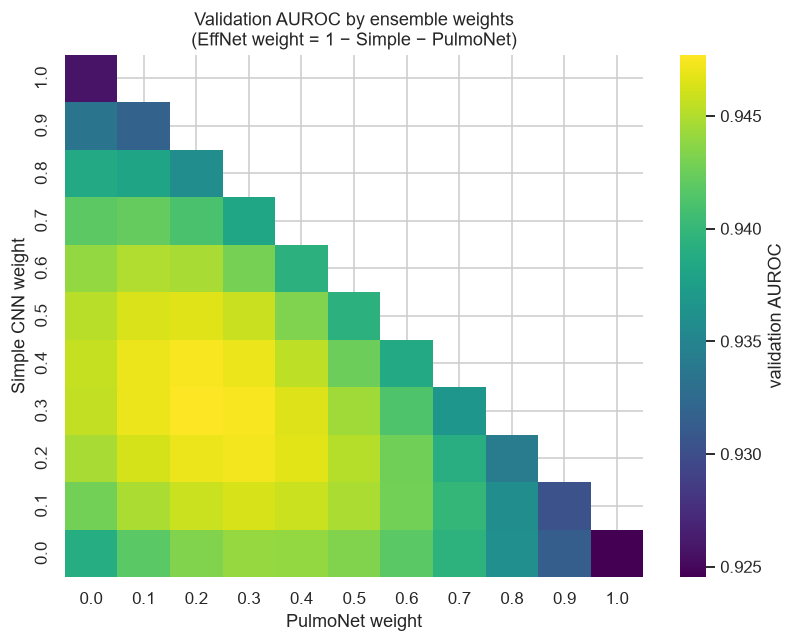

In [12]:
grid = [(a / 10, b / 10, round(1 - a / 10 - b / 10, 1)) for a in range(11) for b in range(11 - a)]
def blend(w, split): return sum(wi * probs[n][split] for wi, n in zip(w, NAMES))
val_auc = {w: roc_auc_score(y_val, blend(w, "val")) for w in grid}
w_best = max(val_auc, key=val_auc.get)
print("Best weights on validation (Simple, PulmoNet, EffNet):", w_best, f"→ val AUROC {val_auc[w_best]:.4f}")
candidates[f"Weighted {w_best}"] = {"members": dict(zip(NAMES, w_best)), "val": blend(w_best, "val"), "test": blend(w_best, "test")}

heat = pd.DataFrame([{"Simple": w[0], "PulmoNet": w[1], "AUROC": a} for w, a in val_auc.items()]).pivot(index="Simple", columns="PulmoNet", values="AUROC")
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(heat.sort_index(ascending=False), cmap="viridis", ax=ax, cbar_kws={"label": "validation AUROC"})
ax.set(title="Validation AUROC by ensemble weights\n(EffNet weight = 1 − Simple − PulmoNet)", xlabel="PulmoNet weight", ylabel="Simple CNN weight")
plt.tight_layout(); plt.show()

## 4. Choose on validation only

In [13]:
for name in NAMES:
    candidates[f"{SHORT[name]} alone"] = {"members": {name: 1.0}, "val": probs[name]["val"], "test": probs[name]["test"]}
for c in candidates.values():
    c["threshold"] = pick_thresholds(y_val, c["val"])["balanced"]
    c["val_auroc"] = roc_auc_score(y_val, c["val"])
    c["val_acc"] = float(((c["val"] >= c["threshold"]) == y_val).mean())
val_table = pd.DataFrame({k: {"val AUROC": c["val_auroc"], "val accuracy": c["val_acc"]} for k, c in candidates.items()}).T
val_table = val_table.sort_values("val AUROC", ascending=False)
display(val_table.style.format({"val AUROC": "{:.4f}", "val accuracy": "{:.1%}"}).highlight_max(color="#c7eadf"))
CHOSEN = val_table.index[0]
print(f"Chosen on validation: {CHOSEN}")

,val AUROC,val accuracy
"Weighted (0.3, 0.2, 0.5)",0.9477,87.3%
Simple + PulmoNet + EffNet,0.9471,87.5%
Simple + EffNet,0.9452,86.7%
PulmoNet + EffNet,0.9433,87.5%
Simple + PulmoNet,0.9394,86.9%
EffNet alone,0.9389,86.4%
Simple alone,0.9257,85.1%
PulmoNet alone,0.9245,86.0%


Chosen on validation: Weighted (0.3, 0.2, 0.5)


## 5. Test set: chosen ensemble vs EfficientNet-B0

In [14]:
ch, eff = candidates[CHOSEN], candidates["EffNet alone"]
res = {CHOSEN: with_ci(y_test, ch["test"], ch["threshold"]), E: with_ci(y_test, eff["test"], eff["threshold"])}
display(pd.DataFrame({n: {k: f"{v[0]:.3f} [{v[1]:.3f}–{v[2]:.3f}]" for k, v in r.items()} for n, r in res.items()}))

(auc1, auc2), p_delong = delong_test(y_test, ch["test"], eff["test"])
r1, r2, p_mc = mcnemar(y_test, ch["test"] >= ch["threshold"], eff["test"] >= eff["threshold"])
acc_ch, acc_eff = res[CHOSEN]["Accuracy"][0], res[E]["Accuracy"][0]
print(f"Accuracy: {acc_ch:.1%} vs {acc_eff:.1%}  (Δ {acc_ch - acc_eff:+.1%})")
print(f"AUROC:    {auc1:.4f} vs {auc2:.4f}  (Δ {auc1 - auc2:+.4f}, DeLong p = {p_delong:.3g})")
print(f"Images only the ensemble gets right: {r1} | only EfficientNet: {r2} | McNemar p = {p_mc:.3g}")

,"Weighted (0.3, 0.2, 0.5)",EfficientNet-B0 (transfer)
AUROC,0.937 [0.926–0.949],0.933 [0.921–0.945]
AUPRC,0.947 [0.936–0.957],0.937 [0.924–0.951]
Accuracy,0.867 [0.850–0.884],0.854 [0.836–0.871]
Sensitivity,0.806 [0.781–0.835],0.828 [0.803–0.854]
Specificity,0.926 [0.907–0.943],0.878 [0.858–0.899]
Precision,0.912 [0.890–0.931],0.866 [0.843–0.890]
NPV,0.834 [0.810–0.859],0.843 [0.818–0.867]
F1,0.856 [0.837–0.873],0.847 [0.828–0.866]
Brier,0.097 [0.088–0.106],0.102 [0.091–0.112]


Accuracy: 86.7% vs 85.4%  (Δ +1.4%)
AUROC:    0.9374 vs 0.9328  (Δ +0.0046, DeLong p = 0.0333)
Images only the ensemble gets right: 45 | only EfficientNet: 22 | McNemar p = 0.00674


## 6. All candidates on the test set (for transparency; not used for the choice)

,chosen,val AUROC,test AUROC,test accuracy,sensitivity,specificity
candidate,,,,,,
"Weighted (0.3, 0.2, 0.5)",✓,0.9477,0.9374,86.7%,80.6%,92.6%
Simple + PulmoNet + EffNet,,0.9471,0.9349,86.9%,83.8%,89.9%
Simple + EffNet,,0.9452,0.9374,86.7%,82.9%,90.2%
PulmoNet + EffNet,,0.9433,0.9307,85.8%,78.7%,92.6%
Simple + PulmoNet,,0.9394,0.9237,86.4%,77.9%,94.4%
EffNet alone,,0.9389,0.9328,85.4%,82.8%,87.8%
Simple alone,,0.9257,0.9160,83.5%,77.7%,89.0%
PulmoNet alone,,0.9245,0.9058,83.5%,74.1%,92.5%


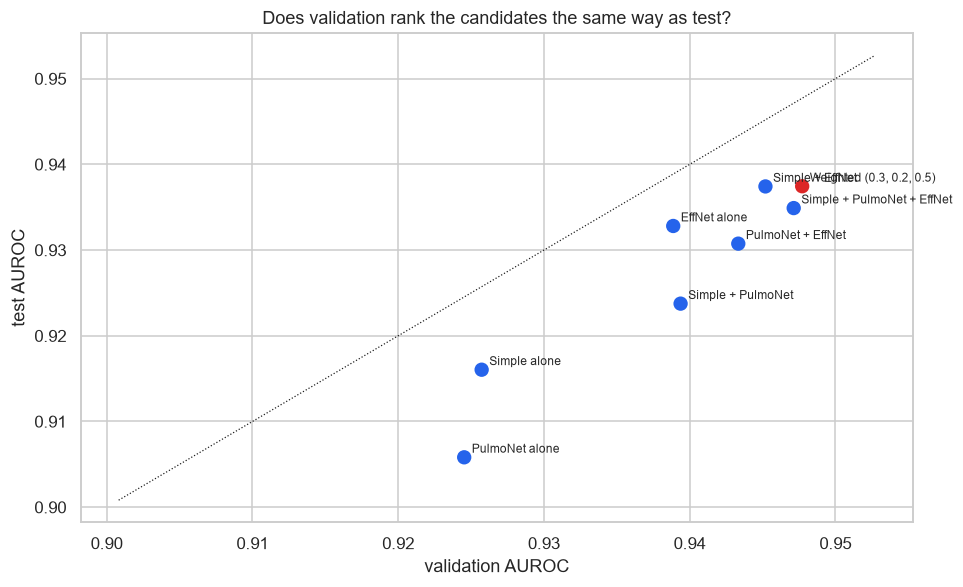

In [15]:
rows = []
for k, c in candidates.items():
    m = point_metrics(y_test, c["test"], c["threshold"])
    rows.append({"candidate": k, "chosen": "✓" if k == CHOSEN else "", "val AUROC": c["val_auroc"],
                 "test AUROC": m["AUROC"], "test accuracy": m["Accuracy"], "sensitivity": m["Sensitivity"], "specificity": m["Specificity"]})
all_test = pd.DataFrame(rows).sort_values("val AUROC", ascending=False).set_index("candidate")
display(all_test.style.format({"val AUROC": "{:.4f}", "test AUROC": "{:.4f}", "test accuracy": "{:.1%}", "sensitivity": "{:.1%}", "specificity": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(all_test["val AUROC"], all_test["test AUROC"], s=70, color=["#DC2626" if c else "#2563EB" for c in all_test.chosen])
for k, r in all_test.iterrows():
    ax.annotate(k, (r["val AUROC"], r["test AUROC"]), fontsize=8, xytext=(5, 3), textcoords="offset points")
lo = min(all_test["val AUROC"].min(), all_test["test AUROC"].min()) - 0.005; hi = max(all_test["val AUROC"].max(), all_test["test AUROC"].max()) + 0.005
ax.plot([lo, hi], [lo, hi], "k:", lw=0.8); ax.set(xlabel="validation AUROC", ylabel="test AUROC", title="Does validation rank the candidates the same way as test?")
plt.tight_layout(); plt.show()

## 7. Export

In [16]:
OUT = ROOT / "results" / "comparison"
from sklearn.metrics import confusion_matrix, roc_curve
fpr, tpr, _ = roc_curve(y_test, ch["test"]); idx = np.unique(np.linspace(0, len(fpr) - 1, 150).astype(int))
export = {"chosen": CHOSEN, "members": {MODELS[n]: w for n, w in ch["members"].items()}, "threshold": ch["threshold"],
          "high_spec_threshold": pick_thresholds(y_val, ch["val"])["high_spec"],
          "confusion_balanced": confusion_matrix(y_test, ch["test"] >= ch["threshold"]).tolist(),
          "roc": [[round(float(fpr[i]), 4), round(float(tpr[i]), 4)] for i in idx],
          "test_metrics": {k: [round(float(x), 4) for x in v] for k, v in res[CHOSEN].items()},
          "effnet_test_metrics": {k: [round(float(x), 4) for x in v] for k, v in res[E].items()},
          "vs_effnet": {"delta_accuracy": round(float(acc_ch - acc_eff), 4), "delta_auroc": round(float(auc1 - auc2), 4),
                        "delong_p": float(f"{p_delong:.3g}"), "mcnemar_p": float(f"{p_mc:.3g}"), "only_ensemble_right": r1, "only_effnet_right": r2},
          "candidates": all_test.reset_index().round(4).to_dict("records")}
(OUT / "ensemble.json").write_text(json.dumps(export, indent=2))
print("Saved", OUT / "ensemble.json")

Saved F:\Projects\pulmoSight\TB Project\results\comparison\ensemble.json
